# Multi-Agent Coordination - Game Theory and VCG

## Problem

Several self-interested agents (advertisers bidding for sponsored-search slots) each want the
best slot they can get. The mechanism decides who gets which slot and what each agent pays.
Two design questions follow:

1. **Efficiency:** can the mechanism give the slots to the agents who value them most?
2. **Incentives:** will each agent report its true value, or will it profit from lying?

The Vickrey-Clarke-Groves (VCG) mechanism is the textbook answer: it is efficient and
dominant-strategy truthful. Pay-your-bid (first-price) and generalised second-price (GSP)
auctions are the common alternatives, and they are not truthful. This notebook implements
VCG for multi-slot allocation from scratch (the allocation is solved with the Hungarian
algorithm), tests truthfulness empirically, and compares welfare and revenue against
first-price and GSP.

## Data

**Simulated, not real.** The market is generated, not downloaded:

- 8 advertisers and 4 sponsored-search slots, one ad per advertiser, one slot per advertiser.
- Each advertiser has a private value per click $v_i \sim \mathrm{LogNormal}(\ln 0.5,\, 0.6)$
  (in dollars) and a public ad-quality score $q_i \sim \mathrm{U}(0.5,\, 1.5)$.
- Click-through follows a documented position-based model: the expected clicks an ad gets in
  slot $j$ are $\mathrm{CTR}_{ij} = q_i\,\alpha_j$, with examination probabilities
  $\alpha = (0.12,\,0.08,\,0.05,\,0.03)$ chosen for this demonstration, not fitted to logs.

The NYC taxi trip data was considered, but it has no natural bidder-item valuation, so it
would need added simulated driver costs anyway. The sponsored-search market was used instead.
No real bid logs are used in this notebook.

## Method

**Setting.** Advertiser $i$ has value $v_i$ per click, so its expected value for slot $j$ is
$v_i\,q_i\,\alpha_j$. It submits a bid $b_i$ and each bidder gets at most one slot. The
allocation maximises the sum of reported values over matchings $x_{ij}\in\{0,1\}$:

$$
x^* = \arg\max_{x} \sum_{i,j} b_i\,q_i\,\alpha_j\,x_{ij}
\quad \text{s.t.}\quad \sum_j x_{ij}\le 1,\ \ \sum_i x_{ij}\le 1 .
$$

This is a linear assignment problem, solved exactly by the Hungarian algorithm
(`scipy.optimize.linear_sum_assignment`). Let $W^*$ be the optimal reported welfare.

**VCG (Clarke pivot).** Winner $i$ pays the externality it imposes on the others:

$$
p_i = W^*_{-i} - \Big(W^* - b_i\,q_i\,\alpha_{j_i}\Big),
$$

where $W^*_{-i}$ is the best reported welfare when bidder $i$ is removed. Utility is
$u_i = v_i\,q_i\,\alpha_{j_i} - p_i$.

**First-price.** Same allocation. Winner pays its bid per click times expected clicks:
$p_i = b_i\,q_i\,\alpha_{j_i}$.

**GSP.** Rank by the score $s_i = b_i q_i$; slot $j$ goes to the $j$-th highest score. The
winner pays the next score times its slot's examination rate: $p_i = s_{(j+1)}\,\alpha_j$.

**Truthfulness test.** A mechanism is truthful if for every value profile and every misreport
$b_i'$, $u_i(v_i) \ge u_i(b_i')$. We sample random markets and misreports, and count how often a
misreport gains.

**Welfare and revenue.** Efficiency is $\mathrm{Welfare}/\mathrm{Welfare}^{\text{opt}}$, where the
optimum is the matching on true values. Revenue is the total payment to the platform.

## Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

SEED = 42
N_ADS, K_SLOTS = 8, 4
ALPHA = np.array([0.12, 0.08, 0.05, 0.03])   # examination probabilities per slot (documented model, not fitted)
pd.set_option("display.width", 160)

def sample_market(rng, n=N_ADS):
    v = rng.lognormal(mean=np.log(0.5), sigma=0.6, size=n)   # private value per click ($)
    q = rng.uniform(0.5, 1.5, size=n)                        # ad quality (public)
    return v, q

print("alpha (slot examination):", ALPHA)

alpha (slot examination): [0.12 0.08 0.05 0.03]


## Mechanisms (from scratch)

In [2]:
def weights(bids, q, alpha=ALPHA):
    # Reported expected value of ad i in slot j.
    return bids[:, None] * q[:, None] * alpha[None, :]

def match(W):
    # Maximum-weight assignment (Hungarian algorithm). linear_sum_assignment minimises cost, so negate.
    rows, cols = linear_sum_assignment(-W)
    assign = {int(r): int(c) for r, c in zip(rows, cols)}
    return assign, float(W[rows, cols].sum())

def run_vcg(bids, q, alpha=ALPHA):
    W = weights(bids, q, alpha)
    assign, total = match(W)
    pay = np.zeros(len(bids))
    for i, j in assign.items():
        others = np.arange(len(bids)) != i
        _, welfare_without_i = match(W[others])           # W*_{-i}
        others_in_chosen = total - W[i, j]                  # others' reported value in the chosen allocation
        pay[i] = welfare_without_i - others_in_chosen       # Clarke pivot payment
    return assign, pay

def run_first_price(bids, q, alpha=ALPHA):
    W = weights(bids, q, alpha)
    assign, _ = match(W)
    pay = np.zeros(len(bids))
    for i, j in assign.items():
        pay[i] = bids[i] * q[i] * alpha[j]                  # own bid per click x expected clicks
    return assign, pay

def run_gsp(bids, q, alpha=ALPHA):
    score = bids * q
    order = np.argsort(-score, kind="stable")
    assign, pay = {}, np.zeros(len(bids))
    for j in range(len(alpha)):
        i = int(order[j])
        assign[i] = j
        pay[i] = score[order[j + 1]] * alpha[j]             # next-ranked score x expected clicks
    return assign, pay

def utility_of(i, assign, pay, v, q, alpha=ALPHA):
    val = v[i] * q[i] * alpha[assign[i]] if i in assign else 0.0
    return val - pay[i]

def welfare_of(assign, v, q, alpha=ALPHA):
    return sum(v[i] * q[i] * alpha[j] for i, j in assign.items())

MECHANISMS = {"VCG": run_vcg, "First-price": run_first_price, "GSP": run_gsp}

### Check 1: the Hungarian allocation equals the sorted (GSP) allocation

The weights factor as $b_i q_i \cdot \alpha_j$. For such separable weights, the optimal
assignment is the sorted matching. The check below confirms that the Hungarian solver and the
sort-based GSP ranking agree on 1,000 random truthful markets.

In [3]:
rng = np.random.default_rng(SEED)
mismatch = 0
for _ in range(1000):
    v, q = sample_market(rng)
    a_h, _ = match(weights(v, q))
    a_g, _ = run_gsp(v, q)
    if set(a_h.items()) != set(a_g.items()):
        mismatch += 1
print("allocation mismatches (Hungarian vs sorted) out of 1000 markets:", mismatch)

allocation mismatches (Hungarian vs sorted) out of 1000 markets: 0


### Check 2: a small VCG example by hand

Three advertisers, two slots, all with quality 1. Ad 0 wins slot 1, ad 1 wins slot 2. The
Clarke payments can be checked by hand: ad 0 displaces ad 1 from slot 1 (payment 0.048), and ad 1
displaces ad 2 from slot 2 (payment 0.024). The printed values should match those.

In [4]:
v_ex = np.array([1.00, 0.60, 0.30])
q_ex = np.ones(3)
a_ex = ALPHA[:2]
assign, pay = run_vcg(v_ex, q_ex, a_ex)
rows = []
for i in range(3):
    j = assign.get(i)
    rows.append({"ad": i, "value/click": v_ex[i], "slot": "-" if j is None else j + 1,
                 "expected clicks": 0.0 if j is None else a_ex[j],
                 "expected value": 0.0 if j is None else v_ex[i] * a_ex[j],
                 "VCG payment": round(pay[i], 4),
                 "utility": round(utility_of(i, assign, pay, v_ex, q_ex, a_ex), 4)})
print(pd.DataFrame(rows).to_string(index=False))
print("social welfare:", round(welfare_of(assign, v_ex, q_ex, a_ex), 4))

 ad  value/click slot  expected clicks  expected value  VCG payment  utility
  0          1.0    1             0.12           0.120        0.048    0.072
  1          0.6    2             0.08           0.048        0.024    0.024
  2          0.3    -             0.00           0.000        0.000    0.000
social welfare: 0.168


## Truthfulness test

We sample random markets (values and qualities). For each market we pick a random advertiser $i$,
compute its utility when it bids truthfully, then compute its utility for 5 random misreports
(bids scaled by a log-uniform factor in $[0.05, 5]$). A *violation* is a misreport that earns
strictly more than truth (tolerance $10^{-9}$). We also check individual rationality (truthful
utility never negative). The test uses 3,000 random markets, which gives 15,000 misreport
comparisons per mechanism.

In [5]:
def truthfulness_test(name, mech, n_trials=3000, n_misreports=5, seed=1):
    rng = np.random.default_rng(seed)
    comparisons = violations = neg_truthful = 0
    max_gain = 0.0
    for _ in range(n_trials):
        v, q = sample_market(rng)
        i = int(rng.integers(N_ADS))
        a_t, p_t = mech(v, q)
        u_t = utility_of(i, a_t, p_t, v, q)
        if u_t < -1e-12:
            neg_truthful += 1
        for _ in range(n_misreports):
            b = v.copy()
            b[i] = v[i] * np.exp(rng.uniform(np.log(0.05), np.log(5.0)))
            a_m, p_m = mech(b, q)
            gain = utility_of(i, a_m, p_m, v, q) - u_t
            comparisons += 1
            if gain > 1e-9:
                violations += 1
                max_gain = max(max_gain, gain)
    return {"mechanism": name, "markets": n_trials, "misreport comparisons": comparisons,
            "misreport beats truth": violations, "violation rate": violations / comparisons,
            "max gain from lying": max_gain, "truthful utility < 0 (IR)": neg_truthful}

t0 = time.time()
truth_df = pd.DataFrame([truthfulness_test(n, m) for n, m in MECHANISMS.items()])
print(truth_df.to_string(index=False))
print(f"(ran in {time.time() - t0:.1f} s)")

  mechanism  markets  misreport comparisons  misreport beats truth  violation rate  max gain from lying  truthful utility < 0 (IR)
        VCG     3000                  15000                      0          0.0000             0.000000                          0
First-price     3000                  15000                    966          0.0644             0.361052                          0
        GSP     3000                  15000                    321          0.0214             0.095603                          0
(ran in 11.1 s)


## Bid shading in a first-price auction (single slot, closed form check)

With $n$ bidders and one slot, values i.i.d. $\mathrm{U}(0,1)$, and first-price payment, the
symmetric equilibrium bid is $b(v) = \frac{n-1}{n} v$. The check below takes $n = 3$. It holds
the other two bidders at $\frac{2}{3} U_j$, and finds the expected-utility-maximising bid for a
bidder with value $0.9$ by Monte Carlo over $200{,}000$ draws. The prediction is $0.6$.

In [6]:
rng = np.random.default_rng(SEED)
n_bidders = 3
v_own = 0.9
others_bids = rng.uniform(0, 1, size=(200_000, n_bidders - 1)) * (n_bidders - 1) / n_bidders
grid_b = np.linspace(0, v_own, 901)
win_prob = np.array([np.mean(others_bids.max(axis=1) < b) for b in grid_b])
exp_util = (v_own - grid_b) * win_prob
b_star = grid_b[int(np.argmax(exp_util))]
print(f"value = {v_own}: best-response bid = {b_star:.3f}  (shading factor {b_star / v_own:.3f})")
print(f"prediction (n-1)/n * v = {(n_bidders - 1) / n_bidders * v_own:.3f}")

value = 0.9: best-response bid = 0.598  (shading factor 0.664)
prediction (n-1)/n * v = 0.600


## Strategic bidding in the multi-slot market

Each advertiser best-responds on a grid of bids (multiples of its true value, from 0 to 1.5),
holding the others fixed. Starting from truthful bids, we run 3 rounds of sequential best
responses. For each mechanism, `strategic` means bidders best-respond under that mechanism and
`truthful` means everyone bids its value. For VCG, truthfulness says the best response should
be the truthful bid, so the best-response dynamics should not move.

In [7]:
GRID = np.linspace(0.0, 1.5, 61)

def best_response(i, bids, v, q, mech):
    utils = np.empty(len(GRID))
    for k, g in enumerate(GRID):
        b = bids.copy()
        b[i] = g * v[i]
        a, p = mech(b, q)
        utils[k] = utility_of(i, a, p, v, q)
    best = utils.max()
    if utils[int(np.argmin(np.abs(GRID - 1.0)))] >= best - 1e-12:
        return 1.0                                         # truthful bid is (weakly) optimal: keep it
    return float(GRID[int(np.argmax(utils >= best - 1e-12))])

def play(v, q, mech, rounds=3):
    bids = v.copy()
    mult = np.ones(len(v))
    for _ in range(rounds):
        for i in range(len(v)):
            mult[i] = best_response(i, bids, v, q, mech)
            bids[i] = mult[i] * v[i]
    return bids, mult

def optimal_welfare(v, q):
    a, _ = match(weights(v, q))
    return welfare_of(a, v, q)

M = 200
rng = np.random.default_rng(SEED)
markets = [sample_market(rng) for _ in range(M)]
opt = np.array([optimal_welfare(v, q) for v, q in markets])

t0 = time.time()
rows, shading, example = [], {}, None
for name, mech in MECHANISMS.items():
    for regime in ("truthful", "strategic"):
        W_sum = R_sum = 0.0
        W_eff = []
        shade = []
        for m, (v, q) in enumerate(markets):
            if regime == "truthful":
                bids, mult = v.copy(), np.ones(N_ADS)
            else:
                bids, mult = play(v, q, mech)
            a, p = mech(bids, q)
            w = welfare_of(a, v, q)
            W_sum += w
            R_sum += p.sum()
            W_eff.append(w / opt[m])
            shade += [mult[i] for i in a]
            if name == "First-price" and regime == "strategic" and example is None and min(mult[i] for i in a) < 0.9:
                example = (m, v, q, bids, mult, a, p)
        shading[(name, regime)] = np.array(shade)
        rows.append({"mechanism": name, "bidding": regime,
                     "welfare/market": W_sum / M, "efficiency": np.mean(W_eff),
                     "revenue/market": R_sum / M, "revenue/welfare": R_sum / W_sum,
                     "mean shading of winners": np.mean(shade)})
print(f"(ran in {time.time() - t0:.1f} s on {M} markets)")
results_df = pd.DataFrame(rows)
print(results_df.round(4).to_string(index=False))

(ran in 156.9 s on 200 markets)
  mechanism   bidding  welfare/market  efficiency  revenue/market  revenue/welfare  mean shading of winners
        VCG  truthful          0.2779      1.0000          0.1582           0.5695                   1.0000
        VCG strategic          0.2779      1.0000          0.1582           0.5695                   1.0000
First-price  truthful          0.2779      1.0000          0.2779           1.0000                   1.0000
First-price strategic          0.2613      0.9442          0.1488           0.5694                   0.7005
        GSP  truthful          0.2779      1.0000          0.1941           0.6986                   1.0000
        GSP strategic          0.2703      0.9729          0.1567           0.5797                   0.8714


### A concrete case of bid shading (first-price)

The first market (in order) where at least one first-price winner shades its bid below 0.9 of
its value. Under the truthful bid a winner gets zero utility (it pays its value), so shading
is the only way it earns surplus.

In [8]:
m, v, q, bids, mult, a, p = example
a_t, p_t = run_first_price(v, q)                       # the same market with truthful bids
rows = []
for i in range(N_ADS):
    won_s = a.get(i)
    rows.append({"ad": i, "value/click": round(v[i], 3), "quality": round(q[i], 3),
                 "strategic multiplier": round(mult[i], 3), "strategic bid": round(bids[i], 3),
                 "slot (strategic)": "-" if won_s is None else won_s + 1,
                 "utility, truthful bid": round(utility_of(i, a_t, p_t, v, q), 4),
                 "utility, strategic bid": round(utility_of(i, a, p, v, q), 4)})
print(f"market index {m}; total welfare truthful = {welfare_of(a_t, v, q):.4f}, strategic = {welfare_of(a, v, q):.4f}")
print(pd.DataFrame(rows).to_string(index=False))

market index 0; total welfare truthful = 0.2419, strategic = 0.2069
 ad  value/click  quality  strategic multiplier  strategic bid slot (strategic)  utility, truthful bid  utility, strategic bid
  0        0.600    0.628                 0.925          0.555                4                    0.0                  0.0008
  1        0.268    0.950                 1.000          0.268                -                    0.0                  0.0000
  2        0.784    0.871                 0.525          0.412                3                    0.0                  0.0162
  3        0.879    1.427                 0.300          0.264                2                    0.0                  0.0702
  4        0.155    1.144                 1.000          0.155                -                    0.0                  0.0000
  5        0.229    1.323                 1.000          0.229                -                    0.0                  0.0000
  6        0.540    0.943                 0

## Figures

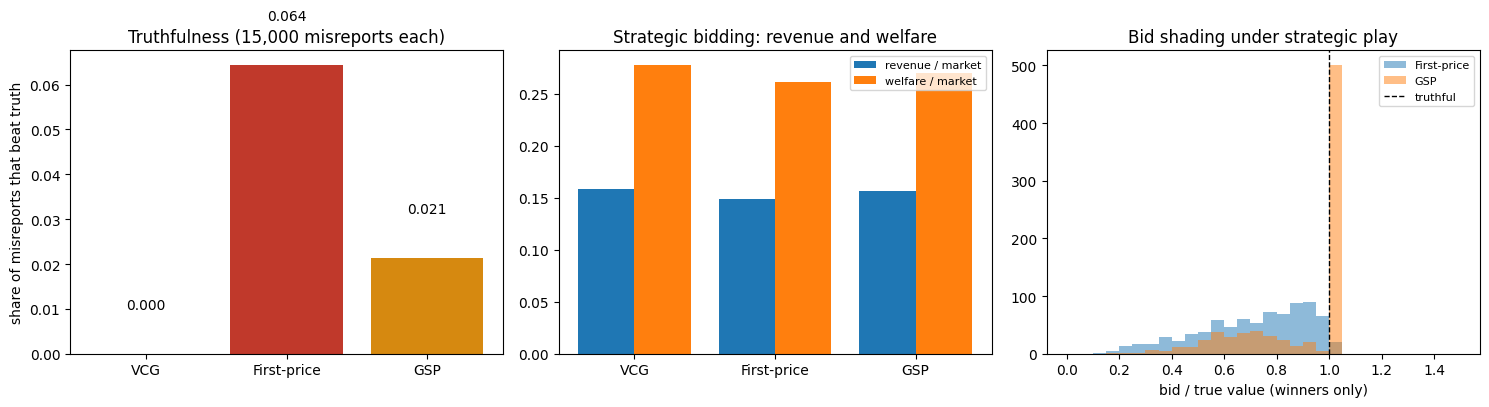

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) truthfulness: violation rate by mechanism
tt = truth_df.set_index("mechanism")["violation rate"]
axes[0].bar(tt.index, tt.values, color=["#2a6f97", "#c0392b", "#d68910"])
for k, val in enumerate(tt.values):
    axes[0].text(k, val + 0.01, f"{val:.3f}", ha="center")
axes[0].set_ylabel("share of misreports that beat truth")
axes[0].set_title("Truthfulness (15,000 misreports each)")

# (b) revenue and efficiency, strategic bidding
sub = results_df[results_df["bidding"] == "strategic"].set_index("mechanism")
x = np.arange(len(sub.index)); w = 0.4
axes[1].bar(x - w / 2, sub["revenue/market"], w, label="revenue / market")
axes[1].bar(x + w / 2, sub["welfare/market"], w, label="welfare / market")
axes[1].set_xticks(x); axes[1].set_xticklabels(sub.index)
axes[1].set_title("Strategic bidding: revenue and welfare"); axes[1].legend(fontsize=8)

# (c) distribution of winners' shading multipliers
for name in ("First-price", "GSP"):
    axes[2].hist(shading[(name, "strategic")], bins=30, range=(0, 1.5), alpha=0.5, label=name)
axes[2].axvline(1.0, color="k", ls="--", lw=1, label="truthful")
axes[2].set_xlabel("bid / true value (winners only)"); axes[2].set_title("Bid shading under strategic play")
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Results

In [10]:
print(truth_df.to_string(index=False))
print()
print(results_df.round(4).to_string(index=False))

  mechanism  markets  misreport comparisons  misreport beats truth  violation rate  max gain from lying  truthful utility < 0 (IR)
        VCG     3000                  15000                      0          0.0000             0.000000                          0
First-price     3000                  15000                    966          0.0644             0.361052                          0
        GSP     3000                  15000                    321          0.0214             0.095603                          0

  mechanism   bidding  welfare/market  efficiency  revenue/market  revenue/welfare  mean shading of winners
        VCG  truthful          0.2779      1.0000          0.1582           0.5695                   1.0000
        VCG strategic          0.2779      1.0000          0.1582           0.5695                   1.0000
First-price  truthful          0.2779      1.0000          0.2779           1.0000                   1.0000
First-price strategic          0.2613      

All numbers below come from the executed outputs above. The market is **simulated** (see Data).

**Hungarian allocation.** On 1,000 truthful markets, the `linear_sum_assignment` allocation matched the sorted GSP allocation in every case (0 mismatches).

**Hand-checked VCG example.** Three advertisers, two slots: VCG payments are 0.0480 (ad 0) and 0.0240 (ad 1), matching the hand calculation. Utilities are 0.0720 and 0.0240.

**Truthfulness (3,000 random markets, 15,000 misreports per mechanism):**

| Mechanism | Misreports that beat truth | Violation rate | Max gain from lying |
|---|---|---|---|
| VCG | 0 / 15,000 | 0.0000 | 0.0000 |
| First-price | 966 / 15,000 | 0.0644 | 0.3611 |
| GSP | 321 / 15,000 | 0.0214 | 0.0956 |

VCG had no negative truthful utilities (individual rationality held in all 3,000 markets).

**Bid shading.** With a single slot, 3 bidders and uniform values, the Monte Carlo best response for value 0.9 is 0.598 (shading factor 0.664), against the closed-form prediction of 0.600.

**Strategic play in the 8-advertiser, 4-slot market (200 markets, 3 best-response rounds):**

| Mechanism | Bidding | Efficiency | Revenue per market | Revenue / welfare | Mean shading of winners |
|---|---|---|---|---|---|
| VCG | truthful = best response | 1.0000 | 0.1582 | 0.5695 | 1.000 |
| First-price | strategic | 0.9442 | 0.1488 | 0.5694 | 0.7005 |
| GSP | strategic | 0.9729 | 0.1567 | 0.5797 | 0.8714 |

The first-price and GSP "truthful" rows are shown only for reference. Bidding true values in a first-price auction is not an equilibrium, since winners then earn zero surplus. Under strategic bidding, VCG earned the highest revenue per market (0.1582, against 0.1567 for GSP and 0.1488 for first-price), and it was the only mechanism at full efficiency.

**Shading case.** In market 0, advertiser 3 (value 0.879) bids 0.300 of its value (bid 0.264) and wins slot 2. Its utility is 0.0702, against 0.0 if it had bid truthfully and paid 0.879 per click.

**Caveats.**
- The market, click model and value distributions are simulated. The click model is a separable position-based model with examination rates chosen for this demonstration, not fitted to real logs, so the revenue ranking depends on that model.
- The revenue gap between VCG (0.1582) and first-price (0.1488) is about 6%. It was not tested for statistical significance over 200 markets, so treat it as indicative.
- Best-response dynamics ran for 3 rounds on a 61-point bid grid (0.025 resolution). Convergence was not checked beyond that.
- The truthfulness test samples misreports at random, so it cannot prove truthfulness. It only shows no violation in 15,000 trials. VCG's truthfulness is a theorem; the test is a check on the implementation.

## Conclusions
1. **VCG is truthful; the alternatives are not.** Over 15,000 misreports in 3,000 simulated markets, lying never beat honest bidding under VCG (0 violations), while it paid off in 2.14% of cases under GSP (maximum gain 0.096) and in 6.44% under first-price (maximum gain 0.361).
2. **Strategic bidding costs efficiency under first-price and GSP.** With strategic bidders, VCG keeps efficiency at 1.000, GSP drops to 0.973 and first-price to 0.944. First-price winners shade their bids to about 70% of their value on average.
3. **Revenue is not what the textbook predicts for truthful bidding.** With honest bids, first-price earns the most (0.2779 per market, all of the welfare) and VCG the least (0.1582), but under strategic play revenues converge (VCG 0.1582, GSP 0.1567, first-price 0.1488). The revenue gaps were not tested for significance, so the safe reading is that VCG gives up no revenue relative to the alternatives once bidders adapt.
4. **Limits.** The market is simulated with a documented position-based click model (a real taxi dataset was available but has no natural bidder valuations), best-response dynamics ran for only 3 rounds without a convergence check, and real ad auctions add reserve prices, quality scores and budgets.

**Takeaway for the interview:** VCG makes honesty the best strategy by charging each winner the harm they cause others; it buys simplicity for the bidders at the price of a more complex payment calculation.